> 🔓 **SOLUTIONS EDITION**: this is the instructor copy with worked solutions and executed outputs. Please attempt every problem in the student notebook first; struggling is where learning happens.

# 📘 Lesson 5: Random Forest Regression
*The wisdom of a crowd of slightly-different trees*

| ⏱️ Time | 🎚️ Level | 🧰 Prerequisites |
|---|---|---|
| ~120 min | 🟡 Intermediate | Lesson 04 (Decision Trees); basic probability |

---
## 🎬 The Hook
In 1906 the statistician Francis Galton visited a country fair where 787 people guessed the weight of an ox. Individually, the guesses were all over the place: butchers and farmers mixed with random passers-by. But the **average** of all the guesses was off by less than 1 %.

Why? Each person's error was partly random, and random errors in opposite directions **cancel when averaged**. Last lesson our decision tree was exactly that kind of noisy guesser: brilliant, but different every time we changed the data. Today we hire **hundreds** of trees and let them vote.

---
## 🎯 Learning Objectives
By the end of this notebook you will be able to:

1. Explain **bagging** and **random feature subsets**, and why together they turn weak, unstable trees into a strong model.
2. Use the variance formula for averaged estimators to predict when averaging helps.
3. Compute out-of-bag (OOB) predictions and use them as a free validation set.
4. Implement a Random Forest **from scratch** and compare it with `RandomForestRegressor`.
5. Tune `n_estimators`, `max_features`, `min_samples_leaf`, and read the effect of each.
6. Use permutation importance and partial dependence to interpret a forest.
7. Produce honest prediction intervals from OOB residuals.

## 🗺️ Roadmap

- Why averaging works (the variance formula)
- Bagging & the bootstrap (and the 63.2 % surprise)
- Random feature subsets: decorrelating the crowd
- From scratch + OOB score
- How many trees? Which max_features?
- Interpreting a forest: permutation importance & partial dependence
- Uncertainty: prediction intervals
- Head-to-head: tree vs forest vs linear
- Cheat-sheet, worked examples, problems, quiz

> 💡 **How to use this notebook:** run cells top to bottom. Read the text *before* you run the code. When you reach a 🧩 **Problem**, try it yourself first, open the hints one at a time, and only then peek at the solutions notebook.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))      # so we can import course_utils.py
from course_utils import *                      # np, pd, plt, check(), data_path(), ...
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
RANDOM_STATE = 42
print("Setup complete ✅")
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold

Setup complete ✅


---
## 📐 1. Why averaging works: the variance formula

Suppose we have $B$ estimators (trees), each with variance $\sigma^2$ and **pairwise correlation** $\rho$. The variance of their *average* is

$$\text{Var}\Big(\frac1B\sum_{b=1}^B \hat f_b\Big)=\rho\,\sigma^2+\frac{1-\rho}{B}\,\sigma^2$$

Two regimes tell the whole story:

- If the trees were **independent** ($\rho=0$) the variance falls like $\sigma^2/B$: keep adding trees and it vanishes.
- If the trees are **identical** ($\rho=1$) the average is no better than one tree.
- In between, the variance can never drop below the floor $\rho\sigma^2$: **more trees can't fix correlation**.

So the recipe for a great ensemble is: *low-bias, high-variance* base learners (deep trees ✓) that are as **uncorrelated** as possible. Random Forests achieve decorrelation with two kinds of randomness.

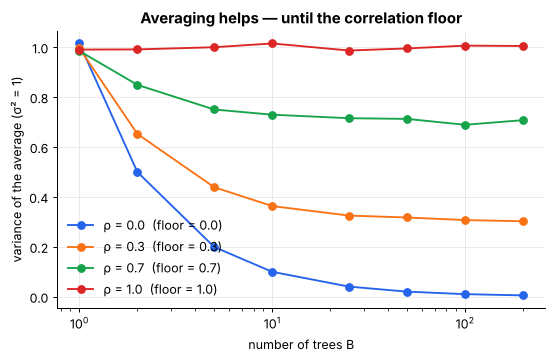

In [2]:
rng = np.random.default_rng(0)
Bs = [1, 2, 5, 10, 25, 50, 100, 200]
fig, ax = plt.subplots(figsize=(7, 4))
for rho in [0.0, 0.3, 0.7, 1.0]:
    emp = []
    for B in Bs:
        common = rng.normal(size=20000)                                  # error shared by all trees
        indiv = rng.normal(size=(20000, B))                              # each tree's own error
        errs = np.sqrt(rho) * common[:, None] + np.sqrt(1 - rho) * indiv  # every tree has variance 1, pairwise corr = rho
        emp.append(errs.mean(axis=1).var())
    ax.plot(Bs, emp, "o-", label=f"ρ = {rho}  (floor = {rho})")
ax.set_xscale("log"); ax.set_xlabel("number of trees B"); ax.set_ylabel("variance of the average (σ² = 1)")
ax.legend(); ax.set_title("Averaging helps; until the correlation floor"); plt.show()

---
## 🎲 2. Randomness #1: bagging (bootstrap aggregating)

To make trees different we give each one a **different training set**: a *bootstrap sample*: draw $n$ rows **with replacement** from the $n$ training rows. Some rows appear twice or three times, others not at all. A fascinating consequence:

In [3]:
n = 1000; rng = np.random.default_rng(1)
fracs = [len(np.unique(rng.integers(0, n, n))) / n for _ in range(300)]
print(f"Average fraction of distinct rows in a bootstrap sample: {np.mean(fracs):.4f}")
print(f"Theory: 1 - (1 - 1/n)^n = {1 - (1 - 1/n) ** n:.4f}   (→ 1 - 1/e = {1 - np.exp(-1):.4f} as n grows)")

Average fraction of distinct rows in a bootstrap sample: 0.6324
Theory: 1 - (1 - 1/n)^n = 0.6323   (→ 1 - 1/e = 0.6321 as n grows)


Each tree sees only **≈ 63.2 %** of the rows. The other **≈ 36.8 %** are its **out-of-bag (OOB)** rows: data this tree has *never seen*. That means for every training row we can collect predictions from the ~37 % of trees that didn't train on it, average them, and compare with the truth: a **free, honest validation score without a separate validation set**.

> 🔑 **Key idea.**
>
> Bagging reduces variance. Random Forest then adds **Randomness #2**: at every split, the tree may only consider a random subset of `max_features` features. This stops every tree from choosing the same dominant feature (like `sqft`) at the root, which lowers the correlation ρ between trees, and ρ is the floor on the ensemble's variance.

---
## 🔧 3. Build it from scratch

A random forest is a `for` loop: bootstrap → grow a tree with random feature subsets → store. Prediction = average. (For the individual trees we reuse scikit-learn's `DecisionTreeRegressor`, which we proved in Lesson 04 to be the same CART algorithm we wrote by hand; its `max_features` argument implements the random subsets.)

In [4]:
houses = pd.read_csv(data_path("house_prices.csv"))
hc = houses[houses["sqft"] <= 6500].reset_index(drop=True)
num_cols = ["sqft", "bedrooms", "bathrooms", "age_years", "garage_spaces", "has_pool", "distance_to_cbd_km", "lot_size_sqft"]
Xall = pd.get_dummies(hc[num_cols + ["neighborhood"]], columns=["neighborhood"], dtype=float)
Xall["condition_ord"] = hc["condition"].map({"Poor": 0, "Fair": 1, "Good": 2, "Excellent": 3})
yall = hc["price_million_kes"]
Xtr, Xte, ytr, yte = train_test_split(Xall, yall, test_size=0.2, random_state=RANDOM_STATE)
med = Xtr.median(); Xtr, Xte = Xtr.fillna(med), Xte.fillna(med)
Xtr, Xte = Xtr.astype(float), Xte.astype(float)      # (scikit-learn's partial-dependence tools insist on float columns)
print("train:", Xtr.shape, "test:", Xte.shape)

train: (1595, 21) test: (399, 21)


In [5]:
class RandomForestRegressorScratch:
    """Random forest = bootstrap samples + random feature subsets + averaging. Also computes the OOB score."""

    def __init__(self, n_estimators=100, max_features=0.33, min_samples_leaf=2, max_depth=None, random_state=0):
        self.n_estimators, self.max_features = n_estimators, max_features
        self.min_samples_leaf, self.max_depth, self.random_state = min_samples_leaf, max_depth, random_state

    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y, float); n = len(y)
        rng = np.random.default_rng(self.random_state)
        self.trees_ = []
        oob_sum, oob_cnt = np.zeros(n), np.zeros(n)
        for _ in range(self.n_estimators):
            idx = rng.integers(0, n, n)                                   # 1) bootstrap sample (with replacement)
            tree = DecisionTreeRegressor(max_features=self.max_features,  # 2) random feature subset at EVERY split
                                         min_samples_leaf=self.min_samples_leaf, max_depth=self.max_depth,
                                         random_state=int(rng.integers(1 << 30)))
            tree.fit(X[idx], y[idx])
            self.trees_.append(tree)
            oob = np.setdiff1d(np.arange(n), idx)                         # rows this tree never saw
            oob_sum[oob] += tree.predict(X[oob]); oob_cnt[oob] += 1
        seen = oob_cnt > 0
        self.oob_prediction_ = np.where(seen, oob_sum / np.maximum(oob_cnt, 1), np.nan)
        self.oob_score_ = 1 - np.sum((y[seen] - self.oob_prediction_[seen]) ** 2) / np.sum((y[seen] - y[seen].mean()) ** 2)
        return self

    def predict_all(self, X):                                             # B x n matrix of individual tree predictions
        X = np.asarray(X, float)
        return np.array([t.predict(X) for t in self.trees_])

    def predict(self, X):
        return self.predict_all(X).mean(axis=0)                           # 3) average the crowd

    def score(self, X, y):
        y = np.asarray(y, float); return 1 - np.sum((y - self.predict(X)) ** 2) / np.sum((y - y.mean()) ** 2)


mine = RandomForestRegressorScratch(n_estimators=100, max_features=0.33, min_samples_leaf=2).fit(Xtr.values, ytr.values)
ref = RandomForestRegressor(n_estimators=100, max_features=0.33, min_samples_leaf=2, oob_score=True, random_state=0).fit(Xtr, ytr)
single = DecisionTreeRegressor(min_samples_leaf=2, random_state=0).fit(Xtr, ytr)
print(f"{'Single tree':<22} test R² = {single.score(Xte, yte):.3f}")
print(f"{'Scratch forest':<22} test R² = {mine.score(Xte.values, yte.values):.3f}   OOB R² = {mine.oob_score_:.3f}")
print(f"{'sklearn forest':<22} test R² = {ref.score(Xte, yte):.3f}   OOB R² = {ref.oob_score_:.3f}")

Single tree            test R² = 0.773
Scratch forest         test R² = 0.907   OOB R² = 0.920
sklearn forest         test R² = 0.897   OOB R² = 0.914


> 🔑 **Key idea.**
>
> Our 30-line loop performs like scikit-learn's forest (the tiny differences come from different random draws), and *dramatically* beats the single tree it is made of. Notice also that the **OOB score ≈ test score**: it really is a free validation estimate.

---
## 🌲 4. How many trees? Which `max_features`?

### 4a. More trees never hurt (just cost time)
Averaging more trees only reduces variance, so the error falls and then **plateaus**: a forest does *not* overfit by adding trees. Let's trace the test error as we average the first 1, 2, 3, … trees of one big forest.

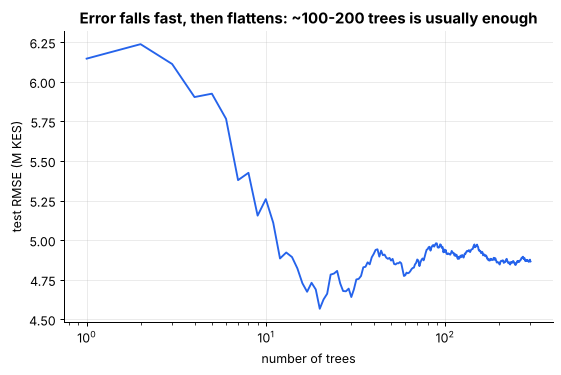

1 tree: RMSE 6.15  |  10 trees: 5.26  |  100 trees: 4.93  |  300 trees: 4.87


In [6]:
big = RandomForestRegressor(n_estimators=300, max_features=0.33, min_samples_leaf=2, random_state=0, n_jobs=-1).fit(Xtr, ytr)
all_preds = np.array([t.predict(Xte.values) for t in big.estimators_])        # 300 x n_test
running = np.cumsum(all_preds, axis=0) / np.arange(1, 301)[:, None]
rmse_curve = np.sqrt(((running - yte.values) ** 2).mean(axis=1))
plt.plot(np.arange(1, 301), rmse_curve); plt.xscale("log"); plt.xlabel("number of trees"); plt.ylabel("test RMSE (M KES)")
plt.title("Error falls fast, then flattens: ~100-200 trees is usually enough"); plt.show()
print(f"1 tree: RMSE {rmse_curve[0]:.2f}  |  10 trees: {rmse_curve[9]:.2f}  |  100 trees: {rmse_curve[99]:.2f}  |  300 trees: {rmse_curve[-1]:.2f}")

### 4b. `max_features`: the decorrelation dial
Small `max_features` → trees are forced to use different features (low ρ) but each tree is individually weaker (higher bias). Large → strong, but similar trees. Let's measure both quantities.

In [7]:
rows = []
for mf in [0.1, 0.2, 0.33, 0.5, 0.75, 1.0]:
    rf = RandomForestRegressor(n_estimators=100, max_features=mf, min_samples_leaf=2, random_state=0, n_jobs=-1).fit(Xtr, ytr)
    P = np.array([t.predict(Xte.values) for t in rf.estimators_[:40]])
    C = np.corrcoef(P); rho = (C.sum() - len(C)) / (len(C) * (len(C) - 1))     # average pairwise correlation of trees
    rows.append({"max_features": mf, "avg tree-to-tree correlation ρ": rho, "test R²": rf.score(Xte, yte)})
display(pd.DataFrame(rows).round(3))

,max_features,avg tree-to-tree correlation ρ,test R²
0,0.10,0.733,0.888
1,0.20,0.787,0.896
2,0.33,0.820,0.897
3,0.50,0.859,0.892
4,0.75,0.876,0.900
5,1.00,0.894,0.903


As `max_features` shrinks the trees decorrelate (ρ falls) (the *ensemble* benefits) but at some point the individual trees become too weak. The best value is data-dependent: tune it. Common starting points: **1/3 of the features for regression**, √p for classification.

---
## 🔎 5. Interpreting a forest

A forest of 200 trees is no longer a flowchart. But it can still *explain* itself.

### 5a. Impurity importance vs permutation importance
- **Impurity importance** (`feature_importances_`): total variance reduction credited to a feature across all splits. Free, but computed on *training* data and **biased towards features with many distinct values**: even pure noise.
- **Permutation importance**: shuffle one feature on *held-out* data and measure how much the score drops. If shuffling doesn't hurt, the model wasn't relying on it.

Let's catch impurity importance red-handed by adding a column of **pure random noise**:

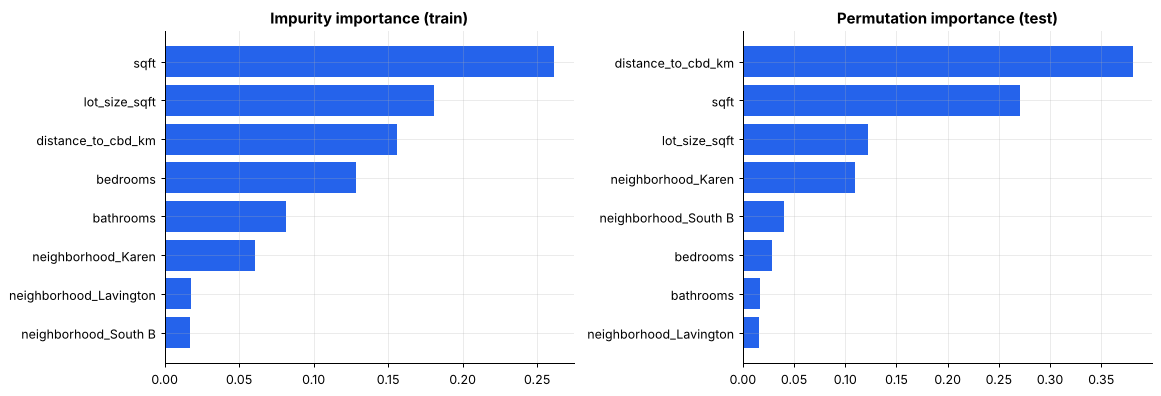

Noise column: impurity importance = 0.0118  |  permutation importance = -0.00133


In [8]:
rng = np.random.default_rng(0)
Xtr_n = Xtr.copy(); Xtr_n["RANDOM_NOISE"] = rng.normal(size=len(Xtr))
Xte_n = Xte.copy(); Xte_n["RANDOM_NOISE"] = rng.normal(size=len(Xte))
rf_n = RandomForestRegressor(n_estimators=200, max_features=0.33, min_samples_leaf=2, random_state=0, n_jobs=-1).fit(Xtr_n, ytr)

imp_imp = pd.Series(rf_n.feature_importances_, index=Xtr_n.columns)
pi = permutation_importance(rf_n, Xte_n, yte, n_repeats=8, random_state=0, n_jobs=-1)
imp_perm = pd.Series(pi.importances_mean, index=Xtr_n.columns)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, s, ttl in [(axes[0], imp_imp, "Impurity importance (train)"), (axes[1], imp_perm, "Permutation importance (test)")]:
    top = s.sort_values().tail(8); colors = ["#dc2626" if i == "RANDOM_NOISE" else "#2563eb" for i in top.index]
    ax.barh(top.index, top.values, color=colors); ax.set_title(ttl)
plt.tight_layout(); plt.show()
print(f"Noise column: impurity importance = {imp_imp['RANDOM_NOISE']:.4f}  |  permutation importance = {imp_perm['RANDOM_NOISE']:.5f}")

The noise column earns a visible share of the impurity importance (it offers many random 'split points') but a permutation importance of ≈ 0: the honest verdict. **Use permutation importance on held-out data when you need to tell a stakeholder what matters.**

### 5b. Partial dependence: *how* does the prediction change with a feature?
Average the model's prediction over the data while sweeping one feature across its range:

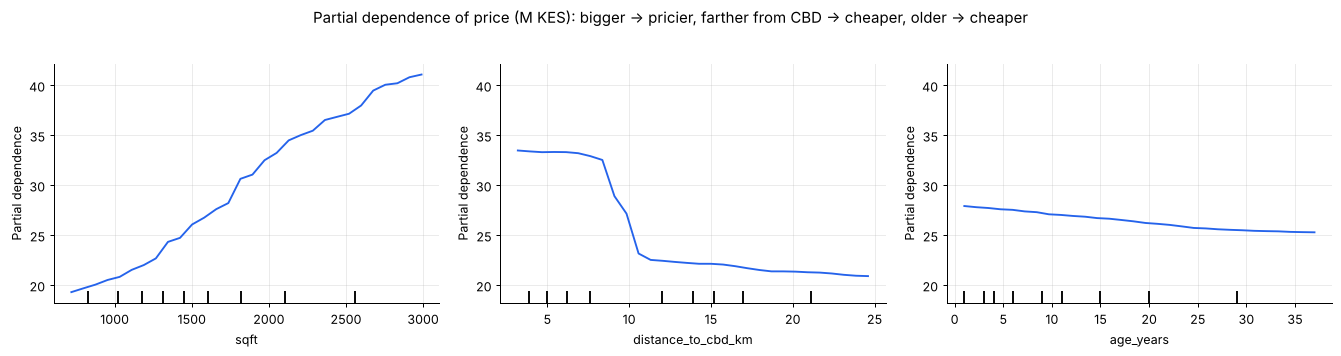

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
PartialDependenceDisplay.from_estimator(ref, Xtr, ["sqft", "distance_to_cbd_km", "age_years"], grid_resolution=30, ax=ax)
plt.suptitle("Partial dependence of price (M KES): bigger → pricier, farther from CBD → cheaper, older → cheaper", y=1.03); plt.tight_layout(); plt.show()

The forest rediscovered the pattern (and the curvature of the size effect) with **no equations and no feature engineering**.

---
## 🎯 6. How sure is the forest? Prediction intervals

A forest produces 300 individual predictions per house. Their spread is *tempting* to use as an interval, but it measures the **trees' disagreement**, which is not calibrated to the real error in prices. Let's test how often the spread-based 80 % interval actually captures the truth:

In [10]:
tree_preds = np.array([t.predict(Xte.values) for t in big.estimators_])         # 300 x n_test
lo, hi = np.percentile(tree_preds, [10, 90], axis=0)
cov_spread = np.mean((yte.values >= lo) & (yte.values <= hi))
print(f"Nominal 80% interval from tree spread actually covers {cov_spread:.0%} of true prices  <- NOT 80%: uncalibrated!")

Nominal 80% interval from tree spread actually covers 93% of true prices  <- NOT 80%: uncalibrated!


Neither too wide nor too narrow is *guaranteed*: the spread of deep, noisy trees simply has no built-in link to the true error (here it happens to be too wide; on other data it can be too narrow). **A better, calibrated recipe uses OOB residuals.** The OOB predictions are *honest* out-of-sample predictions for the training rows, so their residuals $y-\hat y_{OOB}$ show the real error distribution. Add the 10th and 90th percentiles of those residuals to any new prediction:

In [11]:
rf_oob = RandomForestRegressor(n_estimators=300, max_features=0.33, min_samples_leaf=2, oob_score=True, random_state=0, n_jobs=-1).fit(Xtr, ytr)
resid = ytr.values - rf_oob.oob_prediction_
q_lo, q_hi = np.percentile(resid, [10, 90])
pred = rf_oob.predict(Xte)
cov_oob = np.mean((yte.values >= pred + q_lo) & (yte.values <= pred + q_hi))
print(f"OOB-residual 80% interval covers {cov_oob:.0%} of true prices  <- right on the nominal 80%")

OOB-residual 80% interval covers 80% of true prices  <- right on the nominal 80%


> ⚠️ **Watch out.**
>
> In this synthetic data the errors scale with the price (expensive houses are noisier). A *constant-width* interval is therefore too narrow for luxury homes and too wide for cheap ones. For heteroscedastic problems use relative residuals (divide by the prediction) or quantile/conformal methods.

---
## ⚔️ 7. Head-to-head: tree vs forest vs linear

Same train/test split, three models.

In [12]:
sc = StandardScaler().fit(Xtr)
lin = LinearRegression().fit(sc.transform(Xtr), np.log(ytr))
tree = DecisionTreeRegressor(min_samples_leaf=5, random_state=0).fit(Xtr, ytr)
models = {"Decision tree": lambda X: tree.predict(X), "Random forest": lambda X: ref.predict(X),
          "Linear (log price)": lambda X: np.exp(lin.predict(sc.transform(X)))}
tbl = pd.DataFrame({k: {"test R²": r2_score(yte, f(Xte)), "test RMSE": np.sqrt(mean_squared_error(yte, f(Xte))),
                        "median abs % error": 100 * np.median(np.abs(yte - f(Xte)) / yte)} for k, f in models.items()}).T
display(tbl.round(3))

,test R²,test RMSE,median abs % error
Decision tree,0.797,6.907,13.235
Random forest,0.897,4.926,8.250
Linear (log price),0.932,3.985,7.680


The forest closes most of the gap to the linear model, and it did so **without** being told that effects are multiplicative, without scaling and without log transforms. On data with real interactions and thresholds the forest would usually win outright. Here the truth is smooth and nearly log-linear, which is the linear model's home turf.

*Lesson: forests are a superb **default**: robust, low-tuning, hard to break. But a well-specified simple model can still win.*

---
## 📋 8. Cheat-sheet: the full profile of Random Forest Regression

| Question | Answer |
|---|---|
| **Underlying concept** | Average many deep, decorrelated decision trees trained on bootstrap samples with random feature subsets. |
| **How it works** | For b = 1..B: bootstrap the rows → grow a tree (random `max_features` per split) → store. Predict = mean of all trees. OOB rows give a free validation score. |
| **Mathematical foundation** | Variance of an average of correlated estimators: ρσ² + (1−ρ)σ²/B; bootstrap (63.2 % in-bag); bias–variance trade-off. |
| **Important parameters** | `n_estimators` (100–500), `max_features` (≈ p/3 for regression), `min_samples_leaf`, `max_depth`, `bootstrap`, `max_samples`, `oob_score`, `n_jobs`, `random_state`. |
| **Advantages** | Excellent default accuracy; few knobs; no scaling; handles interactions & non-linearity; robust to outliers/noise features; OOB estimate; parallelisable; importance measures. |
| **Disadvantages** | Less interpretable than one tree; can't extrapolate; large models (memory); slower prediction than linear; weaker on very sparse/high-dim text; smooth linear signals are approximated by steps. |
| **Complexity** | Training ≈ O(B · m · n log n) where m = features tried per split (parallel over trees); prediction O(B · depth); memory O(B · nodes). |
| **Use cases** | Tabular data of mixed types: pricing, risk scores, demand/yield prediction, a strong baseline for almost any structured problem. |
| **Limitations** | Piecewise-constant output; extrapolation fails; importance can mislead with correlated features; prediction intervals need extra work (OOB residuals, quantile forests). |

---
## 🧪 9. Worked examples

### Worked Example 1: How much does averaging help?

**Question.** Each tree has variance $\sigma^2=16$ (RMSE-ish 4 units) and the correlation between trees is $\rho=0.25$. Compare $B=1$, $B=10$, $B=100$ and $B=\infty$.

**Solution.** $\text{Var}=\rho\sigma^2+\frac{1-\rho}{B}\sigma^2 = 4+\frac{12}{B}$.

| B | Variance | Std-dev |
|---|---|---|
| 1 | 16 | 4.00 |
| 10 | 5.2 | 2.28 |
| 100 | 4.12 | 2.03 |
| ∞ | 4.0 | 2.00 |

Going from 1 → 10 trees halves the standard deviation; going from 100 → ∞ gains almost nothing. The floor $\rho\sigma^2=4$ can only be lowered by *decorrelating* the trees (smaller `max_features`).

In [13]:
var = lambda s2, rho, B: rho * s2 + (1 - rho) * s2 / B
for B in [1, 10, 100, 10**9]: print(f"B={B:>10}: variance = {var(16, .25, B):6.3f}   std = {np.sqrt(var(16, .25, B)):.3f}")

B=         1: variance = 16.000   std = 4.000
B=        10: variance =  5.200   std = 2.280
B=       100: variance =  4.120   std = 2.030
B=1000000000: variance =  4.000   std = 2.000


### Worked Example 2: Reading OOB

A forest of 300 trees on 1 000 rows. Roughly how many trees have **not** seen a given row?
Each tree excludes a row with probability $(1-1/n)^n\approx0.368$, so about $300\times0.368\approx110$ trees give an out-of-bag prediction for that row: plenty to average, which is why the OOB estimate is stable.

---
### 🧩 Problem 1: Variance of an ensemble  ⭐

Write `ensemble_variance(sigma2, rho, B)` implementing the formula from Section 1. Use it to compute:

- `v_indep`: σ² = 9, ρ = 0, B = 25
- `v_corr`: σ² = 9, ρ = 0.5, B = 25
- `floor`: the limit of the variance for σ² = 9, ρ = 0.5 as B → ∞ (just the formula's floor)
- `B_needed`: the **smallest B** such that the variance for σ² = 9, ρ = 0.5 is within 5 % of that floor.

In [14]:
# ✅ SOLUTION
def ensemble_variance(sigma2, rho, B):
    return rho * sigma2 + (1 - rho) * sigma2 / B

v_indep = ensemble_variance(9, 0, 25)
v_corr = ensemble_variance(9, 0.5, 25)
floor = 0.5 * 9
B_needed = next(B for B in range(1, 10000) if ensemble_variance(9, 0.5, B) <= 1.05 * floor)
print(v_indep, v_corr, floor, B_needed)

0.36 4.68 4.5 20


**Why this works.** With ρ = 0.5 the variance can never fall below 4.5, and 20 trees already get within 5 % of that floor: more trees are wasted; you'd need to reduce ρ instead.

In [15]:
check("independent trees: 9/25 = 0.36", lambda: abs(v_indep - 0.36) < 1e-9)
check("correlated trees: 4.5 + 0.18 = 4.68", lambda: abs(v_corr - 4.68) < 1e-9)
check("floor = 4.5", lambda: abs(floor - 4.5) < 1e-9)
check("B needed = 20", lambda: B_needed == 20)

✅  independent trees: 9/25 = 0.36
✅  correlated trees: 4.5 + 0.18 = 4.68
✅  floor = 4.5
✅  B needed = 20


---
### 🧩 Problem 2: Verify the 63.2 % rule  ⭐

Simulate it yourself: for `n = 5000`, draw one bootstrap sample with `np.random.default_rng(3)` and compute `frac_in_bag` (fraction of *distinct* rows that appear) and `frac_oob = 1 - frac_in_bag`. Also compute `n_oob_trees`, the expected number of trees (out of 500) that treat a given row as out-of-bag.

In [16]:
# ✅ SOLUTION
n = 5000; rng = np.random.default_rng(3)
idx = rng.integers(0, n, n)
frac_in_bag = len(np.unique(idx)) / n
frac_oob = 1 - frac_in_bag
n_oob_trees = 500 * (1 - 1 / n) ** n
print(frac_in_bag, frac_oob, n_oob_trees)

0.628 0.372 183.92132508069855


**Why this works.** 1 − (1 − 1/n)ⁿ → 1 − 1/e ≈ 0.632. Each row is therefore out-of-bag for about 37 % of the trees: 184 of 500.

In [17]:
check("in-bag fraction ≈ 0.632", lambda: abs(frac_in_bag - 0.632) < 0.02)
check("OOB fraction ≈ 0.368", lambda: abs(frac_oob - 0.368) < 0.02)
check("≈ 184 trees see the row as OOB", lambda: abs(n_oob_trees - 184) < 2)

✅  in-bag fraction ≈ 0.632
✅  OOB fraction ≈ 0.368
✅  ≈ 184 trees see the row as OOB


---
### 🧩 Problem 3: Fit a forest and trust the OOB score  ⭐

Fit `RandomForestRegressor(n_estimators=200, max_features=0.33, min_samples_leaf=2, oob_score=True, random_state=0, n_jobs=-1)` on `Xtr, ytr`. Store `oob_r2`, `test_r2` and `gap = abs(oob_r2 - test_r2)`. Then compute `improvement_over_tree`, the test-R² gain versus the lesson's single `tree`.

In [18]:
# ✅ SOLUTION
rf1 = RandomForestRegressor(n_estimators=200, max_features=0.33, min_samples_leaf=2, oob_score=True, random_state=0, n_jobs=-1).fit(Xtr, ytr)
oob_r2 = rf1.oob_score_; test_r2 = rf1.score(Xte, yte); gap = abs(oob_r2 - test_r2)
improvement_over_tree = test_r2 - tree.score(Xte, yte)
print(oob_r2, test_r2, gap, improvement_over_tree)

0.9176341876381704 0.899501430440458 0.018132757197712346 0.10257705679586704


**Why this works.** The OOB estimate (computed on training rows, never touching the test set) predicts the test score within a couple of points: it is a reliable free validation tool, handy when data is too scarce to hold out a test set.

In [19]:
check("test R² > 0.88", lambda: test_r2 > 0.88)
check("OOB and test scores agree (gap < 0.05)", lambda: gap < 0.05)
check("forest beats the single tree by > 0.05 R²", lambda: improvement_over_tree > 0.05)

✅  test R² > 0.88
✅  OOB and test scores agree (gap < 0.05)
✅  forest beats the single tree by > 0.05 R²


---
### 🧩 Problem 4: Tune the forest  ⭐⭐

Use `GridSearchCV` (3-fold, `scoring='r2'`, `n_jobs=-1`) over `max_features ∈ [0.2, 0.33, 0.5, 1.0]` and `min_samples_leaf ∈ [1, 3, 5]` for a `RandomForestRegressor(n_estimators=100, random_state=0)`. Store the winning parameters in `best_params`, and the test R² of the refit best model in `tuned_test_r2`.

In [20]:
# ✅ SOLUTION
gs = GridSearchCV(RandomForestRegressor(n_estimators=100, random_state=0), {"max_features": [0.2, 0.33, 0.5, 1.0], "min_samples_leaf": [1, 3, 5]},
                  cv=3, scoring="r2", n_jobs=-1).fit(Xtr, ytr)
best_params = gs.best_params_; tuned_test_r2 = gs.best_estimator_.score(Xte, yte)
print(best_params, round(tuned_test_r2, 3))

{'max_features': 0.5, 'min_samples_leaf': 1} 0.906


**Why this works.** Forests are famously forgiving: many settings land within a point or two of each other. Tuning gives small, safe gains: the big wins come from features and data quality.

In [21]:
check("found parameters", lambda: set(best_params) == {"max_features", "min_samples_leaf"})
check("tuned test R² > 0.88", lambda: tuned_test_r2 > 0.88)

✅  found parameters
✅  tuned test R² > 0.88


---
### 🧩 Problem 5: Which features really matter?  ⭐⭐

Using the lesson's noise-augmented `rf_n`, `Xte_n`, `yte`: compute permutation importance with `n_repeats=10, random_state=1`. Store `top3` (list of the 3 most important feature names, most important first) and `noise_perm` (the permutation importance of `RANDOM_NOISE`). Finally set `noise_is_useless = noise_perm < 0.005`.

In [22]:
# ✅ SOLUTION
pi2 = permutation_importance(rf_n, Xte_n, yte, n_repeats=10, random_state=1, n_jobs=-1)
imp2 = pd.Series(pi2.importances_mean, index=Xte_n.columns).sort_values(ascending=False)
top3 = imp2.index[:3].tolist(); noise_perm = imp2["RANDOM_NOISE"]; noise_is_useless = bool(noise_perm < 0.005)
print(top3, noise_perm)

['distance_to_cbd_km', 'sqft', 'lot_size_sqft'] -0.000852905453900088


**Why this works.** Size and location-related features dominate. Because the noise feature is shuffled on *held-out* data, a model that ignored it loses nothing: its importance is zero.

In [23]:
check("sqft is in the top 3", lambda: "sqft" in top3)
check("noise column has ~zero permutation importance", lambda: noise_is_useless)

✅  sqft is in the top 3
✅  noise column has ~zero permutation importance


---
### 🧩 Problem 6: Build an honest prediction interval  ⭐⭐⭐

Using `rf_oob` (fit with `oob_score=True`) and the 10th/90th percentiles of **relative** OOB residuals `(y − oob_pred) / oob_pred` (this handles the fact that expensive houses are noisier):

1. `r_lo, r_hi` = those percentiles.
2. For the test set, interval = `pred * (1 + r_lo)` … `pred * (1 + r_hi)`.
3. Store the empirical coverage in `cov_rel` and the average interval *width* relative to the prediction in `rel_width`.

In [24]:
# ✅ SOLUTION
rel_resid = (ytr.values - rf_oob.oob_prediction_) / rf_oob.oob_prediction_
r_lo, r_hi = np.percentile(rel_resid, [10, 90])
pred = rf_oob.predict(Xte)
low, high = pred * (1 + r_lo), pred * (1 + r_hi)
cov_rel = np.mean((yte.values >= low) & (yte.values <= high)); rel_width = np.mean((high - low) / pred)
print(cov_rel, rel_width)

0.8095238095238095 0.33529895939033927


**Why this works.** Using relative residuals makes the interval grow with the price, giving similar coverage for cheap and expensive houses: a practical, assumption-light interval method.

In [25]:
check("coverage is near 80% (70-90%)", lambda: 0.70 < cov_rel < 0.90)
check("intervals are reasonably tight (relative width < 0.6)", lambda: rel_width < 0.6)

✅  coverage is near 80% (70-90%)
✅  intervals are reasonably tight (relative width < 0.6)


---
## 🧠 Check Your Understanding
Answer each question in your head (or on paper) *before* opening the answer.

**Q1.** Why do Random Forests use *deep* (low-bias, high-variance) trees rather than shallow ones?

<details><summary>👀 Show answer</summary>

Averaging reduces variance but not bias. So we start from low-bias learners (deep trees) and let averaging remove their variance.

</details>

**Q2.** What two sources of randomness make the trees different?

<details><summary>👀 Show answer</summary>

(1) A bootstrap sample of rows per tree; (2) a random subset of features considered at each split.

</details>

**Q3.** Adding more trees from 200 to 2 000 barely changes the score. Why, and what *would* help?

<details><summary>👀 Show answer</summary>

The variance term (1−ρ)σ²/B is already negligible; only the floor ρσ² remains. Reduce ρ (smaller max_features), improve features, or tune leaf size.

</details>

**Q4.** What is the OOB score and why is it trustworthy?

<details><summary>👀 Show answer</summary>

For each training row, average predictions only from trees that did *not* train on it, then score. Those predictions are on unseen data for each tree, so it's like cross-validation for free.

</details>

**Q5.** Your forest never predicts a price above the maximum training price, even for a mansion twice as large as any seen. Why?

<details><summary>👀 Show answer</summary>

Each tree predicts an average of training targets, so the forest's output stays within the training range: no extrapolation.

</details>

---
## 🔁 Recap

- Random Forest = bagging (bootstrap rows) + random feature subsets + averaging many deep trees.
- Variance of the average = ρσ² + (1−ρ)σ²/B → more trees help up to a correlation floor; decorrelate with `max_features`.
- ≈ 36.8 % of rows are out-of-bag for each tree, giving a free validation score and OOB residuals for intervals.
- Permutation importance (held-out) is more trustworthy than impurity importance; partial dependence shows direction of effects.
- Forests are an excellent default but can't extrapolate, and a well-specified simple model can still win.

### ➡️ Up next: **Support Vector Regression**
Open `06_Support_Vector_Regression.ipynb` when you're ready.

*You did the hard part: you thought about it, not just ran it. See you in the next one!* 🚀